# Analyse des déterminants de la mortalité et de l'espérance de vie

Ce projet explore les facteurs associés à l'espérance de vie à travers le monde.
Les données proviennent de l'OMS et couvrent 193 pays entre 2000 et 2015.

Je voulais comprendre quelles variables économiques, sanitaires, sociales 
sont liées aux écarts d'espérance de vie observés entre pays.

Les relations identifiées dans ce projet sont des associations statistiques.
Elles ne permettent pas à elles seules de conclure à des relations causales.

In [4]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

FIGURES_DIR = Path('figures')
FIGURES_DIR.mkdir(exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

In [5]:
# Chargement des données.
DATA_PATH = Path('../data/Life Expectancy Data.csv')

df = pd.read_csv(DATA_PATH)

# Nettoyage des noms de colonnes — le dataset contient des espaces superflus.
df.columns = df.columns.str.strip()

print(f"{df.shape[0]:,} observations, {df.shape[1]} variables")
print(f"Pays couverts : {df['Country'].nunique()}")
print(f"Période       : {df['Year'].min()} à {df['Year'].max()}")
df.head()

2,938 observations, 22 variables
Pays couverts : 193
Période       : 2000 à 2015


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## Étape 1  Exploration des données

Avant toute modélisation, je veux comprendre la structure du dataset
et l'ampleur des valeurs manquantes.
Le traitement de ces valeurs manquantes sera fait au moment de la modélisation,
pour éviter de modifier les données brutes avant de les avoir bien examinées.

In [6]:
# Structure générale et valeurs manquantes.
print("Valeurs manquantes par variable :")
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

Valeurs manquantes par variable :
Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness  1-19 years                34
thinness 5-9 years                  34
BMI                                 34
Diphtheria                          19
Polio                               19
Life expectancy                     10
Adult Mortality                     10
dtype: int64


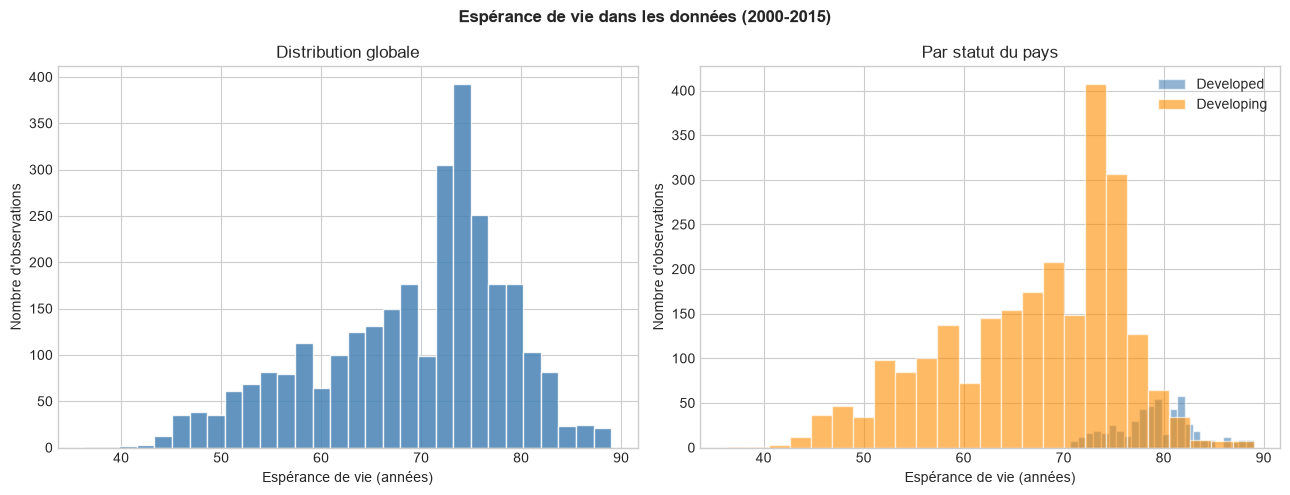

In [7]:
# Distribution de l'espérance de vie selon le statut du pays.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Espérance de vie dans les données (2000-2015)", fontweight='bold')

axes[0].hist(
    df['Life expectancy'].dropna(),
    bins=30, edgecolor='white', alpha=0.85, color='steelblue'
)
axes[0].set_title("Distribution globale")
axes[0].set_xlabel("Espérance de vie (années)")
axes[0].set_ylabel("Nombre d'observations")

for status, color in zip(['Developed', 'Developing'], ['steelblue', 'darkorange']):
    subset = df.loc[df['Status'] == status, 'Life expectancy'].dropna()
    axes[1].hist(subset, bins=25, alpha=0.60, label=status,
                 color=color, edgecolor='white')

axes[1].set_title("Par statut du pays")
axes[1].set_xlabel("Espérance de vie (années)")
axes[1].set_ylabel("Nombre d'observations")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'distribution_esperance_vie.png', dpi=150, bbox_inches='tight')
plt.show()

Les pays développés ont une espérance de vie concentrée autour de 79 à 82 ans.
Les pays en développement montrent une distribution bien plus étalée,
avec des valeurs qui descendent sous 50 ans dans certains cas.
C'est cet écart que je vais tenter d'expliquer.

## Étape 2  facteurs qui sont associés à l'espérance de vie 

Je calcule les corrélations entre les variables numériques et l'espérance de vie.
Une corrélation élevée indique une association linéaire dans cet échantillon.
Elle ne doit pas être interprétée comme une preuve de causalité.

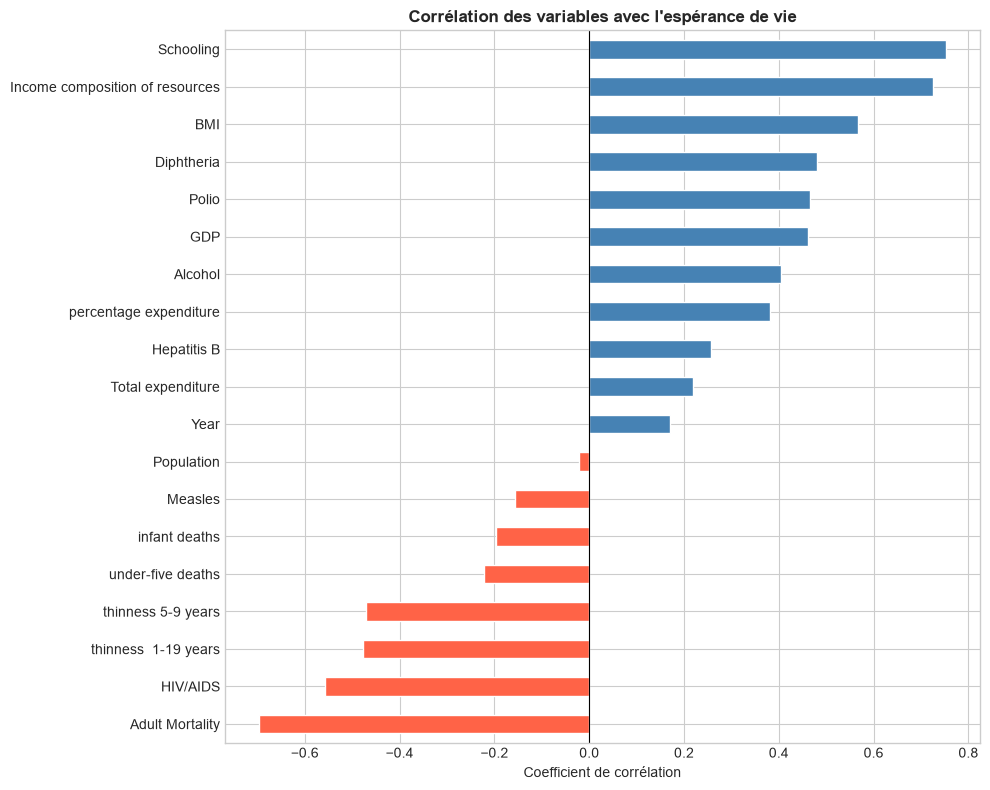

Adult Mortality                   -0.696359
HIV/AIDS                          -0.556556
thinness  1-19 years              -0.477183
thinness 5-9 years                -0.471584
under-five deaths                 -0.222529
infant deaths                     -0.196557
Measles                           -0.157586
Population                        -0.021538
Year                               0.170033
Total expenditure                  0.218086
Hepatitis B                        0.256762
percentage expenditure             0.381864
Alcohol                            0.404877
GDP                                0.461455
Polio                              0.465556
Diphtheria                         0.479495
BMI                                0.567694
Income composition of resources    0.724776
Schooling                          0.751975
Name: Life expectancy, dtype: float64


In [8]:
target       = 'Life expectancy'
numeric_cols = df.select_dtypes(include='number').columns
correlations = df[numeric_cols].corr()[target].drop(target).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['tomato' if x < 0 else 'steelblue' for x in correlations]
correlations.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, linewidth=0.8, color='black')
ax.set_title("Corrélation des variables avec l'espérance de vie", fontweight='bold')
ax.set_xlabel("Coefficient de corrélation")

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'correlations.png', dpi=150, bbox_inches='tight')
plt.show()

print(correlations)

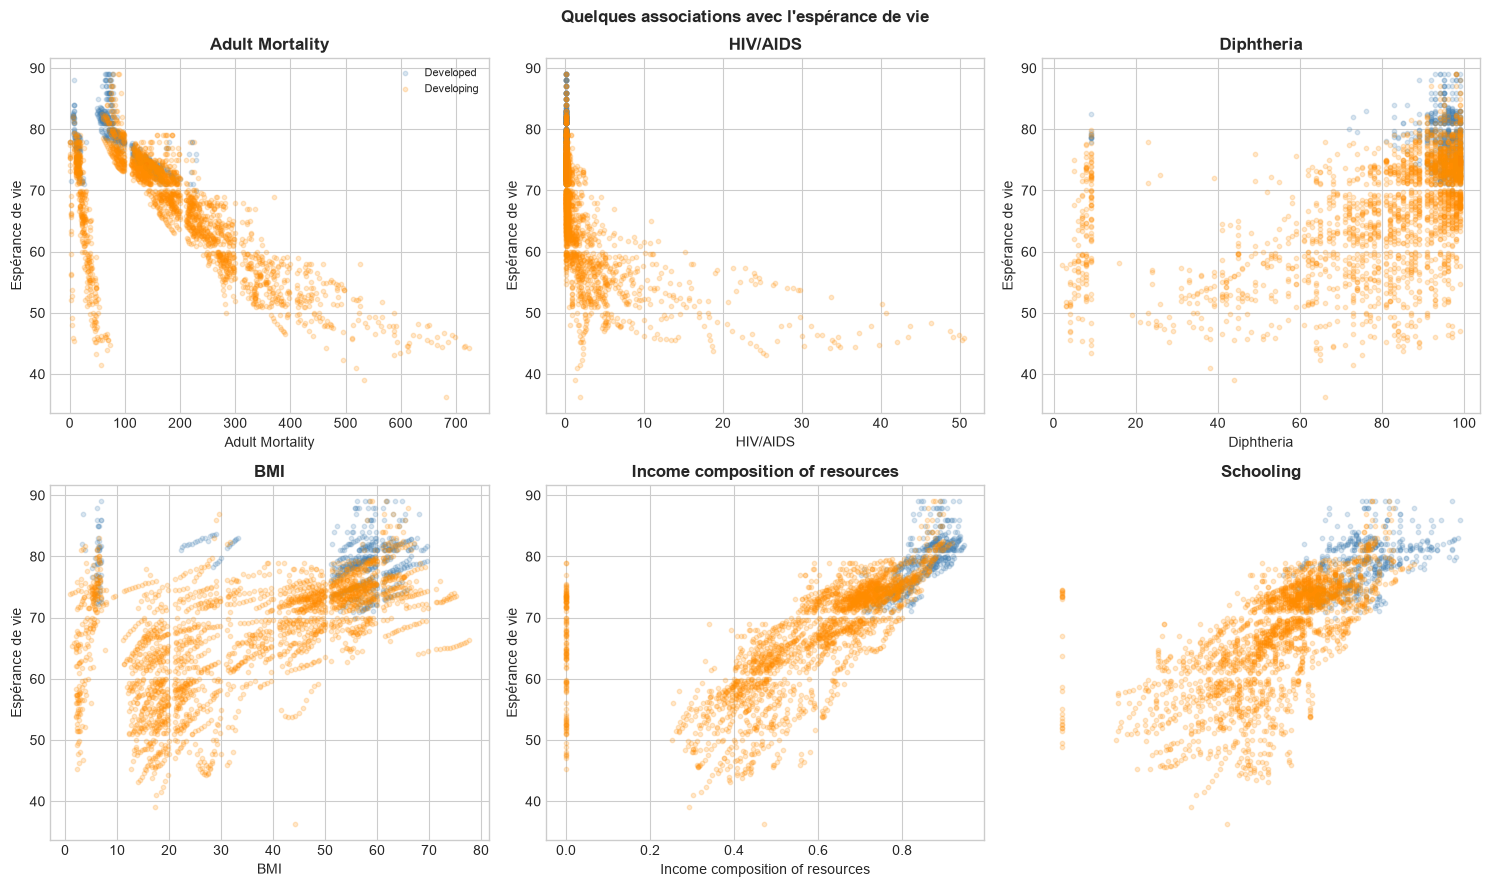

In [9]:
# Zoom sur les variables les plus marquées.
top_negative = correlations.head(2).index.tolist()
top_positive = correlations.tail(4).index.tolist()
top_vars     = top_negative + top_positive

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, var in zip(axes, top_vars):
    for status, color in zip(['Developed', 'Developing'], ['steelblue', 'darkorange']):
        subset = df[df['Status'] == status]
        ax.scatter(subset[var], subset[target],
                   alpha=0.20, s=10, label=status, color=color)
    ax.set_xlabel(var)
    ax.set_ylabel("Espérance de vie")
    ax.set_title(var, fontweight='bold')

axes[0].legend(fontsize=8)
axes[-1].axis('off')

fig.suptitle("Quelques associations avec l'espérance de vie", fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'facteurs_cles.png', dpi=150, bbox_inches='tight')
plt.show()

Dans ces données, la scolarisation et l'indice de composition des revenus
tendent à être associés positivement à l'espérance de vie.
La mortalité adulte et le VIH/SIDA présentent une association négative marquée.

Ces résultats sont des associations bivariées : ils ne tiennent pas compte
des autres variables simultanément.

## Étape 3  Régression linéaire multiple

Je cherche maintenant à expliquer l'espérance de vie à partir de plusieurs variables
simultanément. L'intérêt de la régression multiple est d'estimer l'association
de chaque variable avec l'espérance de vie toutes choses égales par ailleurs,
dans le cadre du modèle choisi.

Pour cette partie, je retire les observations incomplètes sur les variables du modèle
plutôt que d'imputer la variable cible.

In [10]:
features = [
    'Adult Mortality', 'HIV/AIDS', 'GDP',
    'Schooling', 'Income composition of resources',
    'Alcohol', 'BMI', 'Polio', 'Diphtheria'
]

ols_data = df[features + [target]].dropna().copy()

X_ols = sm.add_constant(ols_data[features])
y_ols = ols_data[target]

model = sm.OLS(y_ols, X_ols).fit()

print(f"Observations utilisées : {len(ols_data)}")
print(f"R²          : {model.rsquared:.3f}")
print(f"R² ajusté   : {model.rsquared_adj:.3f}")

Observations utilisées : 2304
R²          : 0.830
R² ajusté   : 0.829


In [11]:
# Tableau des coefficients avec intervalles de confiance à 95%.
coefs = pd.DataFrame({
    'coefficient' : model.params,
    'IC 95% inf'  : model.conf_int()[0],
    'IC 95% sup'  : model.conf_int()[1],
    'p valeur'    : model.pvalues,
}).drop('const').round(4)

coefs['significatif'] = coefs['p valeur'] < 0.05
print(coefs.sort_values('coefficient'))

                                 coefficient  IC 95% inf  IC 95% sup  \
HIV/AIDS                             -0.4882     -0.5231     -0.4532   
Alcohol                              -0.0291     -0.0792      0.0209   
Adult Mortality                      -0.0165     -0.0182     -0.0148   
GDP                                   0.0001      0.0000      0.0001   
Polio                                 0.0225      0.0126      0.0324   
Diphtheria                            0.0323      0.0224      0.0421   
BMI                                   0.0433      0.0328      0.0537   
Schooling                             0.9497      0.8557      1.0438   
Income composition of resources       7.8204      6.4979      9.1428   

                                 p valeur  significatif  
HIV/AIDS                           0.0000          True  
Alcohol                            0.2542         False  
Adult Mortality                    0.0000          True  
GDP                                0.0000      

RMSE : 4.008 années
MAE  : 2.977 années


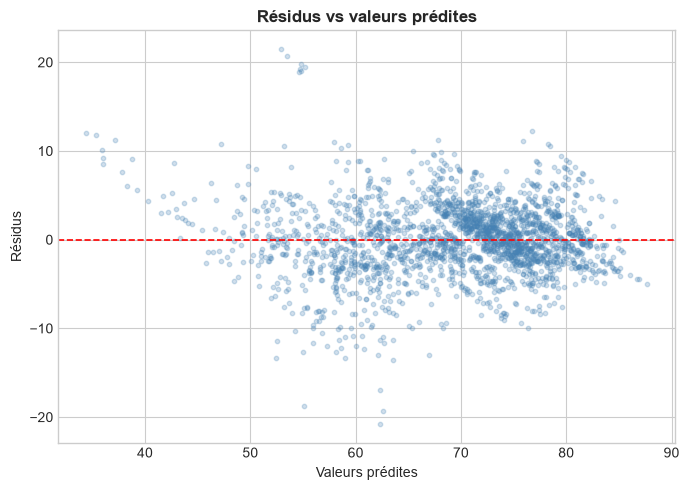

In [12]:
# Performance du modèle — RMSE et MAE sur les données utilisées.
y_pred_ols = model.fittedvalues
residus    = y_ols - y_pred_ols

rmse = np.sqrt((residus ** 2).mean())
mae  = residus.abs().mean()

print(f"RMSE : {rmse:.3f} années")
print(f"MAE  : {mae:.3f} années")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred_ols, residus, alpha=0.25, s=10, color='steelblue')
ax.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax.set_xlabel("Valeurs prédites")
ax.set_ylabel("Résidus")
ax.set_title("Résidus vs valeurs prédites", fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'residus_ols.png', dpi=150, bbox_inches='tight')
plt.show()

Les coefficients indiquent l'association estimée entre chaque variable
et l'espérance de vie lorsque les autres variables restent constantes.

Dans ce modèle, la scolarisation présente le coefficient positif le plus élevé
parmi les variables significatives. La mortalité adulte et le VIH/SIDA
ont les associations négatives les plus marquées.

Ces résultats dépendent des variables incluses, du dataset utilisé
et de la période 2000 à 2015. Ils ne doivent pas être interprétés
comme des relations de cause à effet.

## Étape 4  Classification : pays développé ou en développement 

Je me pose maintenant une question différente : peut-on distinguer les pays développés
des pays en développement à partir de ces indicateurs de santé ?

Un point méthodologique important ici : le dataset contient plusieurs années
pour un même pays. Un découpage aléatoire laisserait le même pays apparaître
à la fois dans le train et dans le test, ce qui biaiserait l'évaluation.
Je sépare donc les données par pays entiers, avec GroupShuffleSplit.

In [13]:
# Variable cible binaire.
df['Status_bin'] = (df['Status'] == 'Developed').astype(int)

X_clf = df[features].copy()
y_clf = df['Status_bin']
groups = df['Country']

# Séparation par pays : aucun pays n'est présent dans les deux ensembles.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X_clf, y_clf, groups=groups))

X_train = X_clf.iloc[train_idx]
X_test  = X_clf.iloc[test_idx]
y_train = y_clf.iloc[train_idx]
y_test  = y_clf.iloc[test_idx]

print(f"Observations train : {len(X_train)}")
print(f"Observations test  : {len(X_test)}")
print(f"Pays dans le train : {groups.iloc[train_idx].nunique()}")
print(f"Pays dans le test  : {groups.iloc[test_idx].nunique()}")

Observations train : 2344
Observations test  : 594
Pays dans le train : 154
Pays dans le test  : 39


In [14]:
# Pipeline : imputation par la médiane, standardisation, régression logistique.
# Tout le prétraitement est appris sur le train uniquement — aucune fuite de données.
clf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('model',   LogisticRegression(max_iter=1000, random_state=42)),
])

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(f"Accuracy          : {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(
    y_test, y_pred,
    target_names=['Developing', 'Developed'],
    zero_division=0
))

Accuracy          : 0.884
Balanced accuracy : 0.877

              precision    recall  f1-score   support

  Developing       0.97      0.89      0.93       482
   Developed       0.64      0.87      0.74       112

    accuracy                           0.88       594
   macro avg       0.80      0.88      0.83       594
weighted avg       0.91      0.88      0.89       594



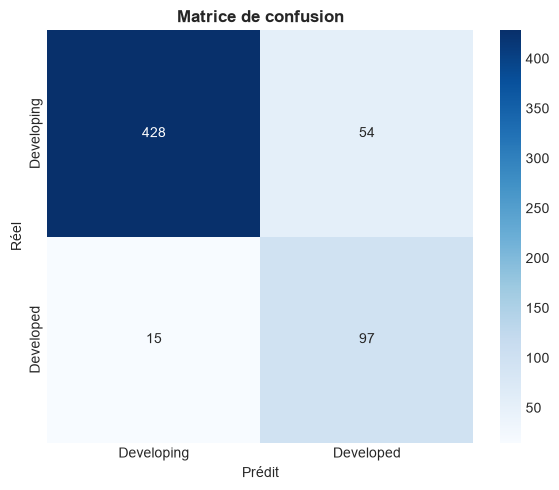

In [15]:
# Matrice de confusion.
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Developing', 'Developed'],
    yticklabels=['Developing', 'Developed'],
    ax=ax
)
ax.set_title('Matrice de confusion', fontweight='bold')
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'matrice_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

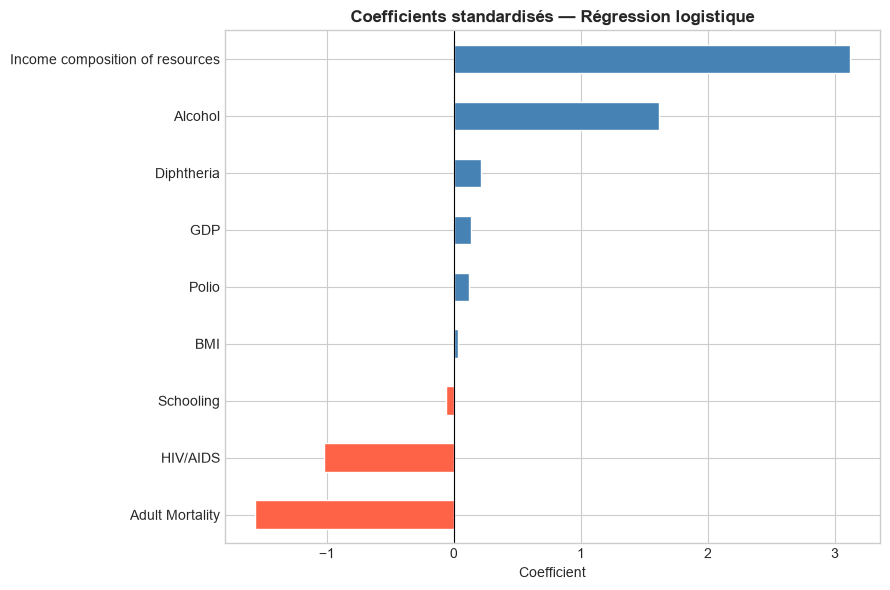

In [16]:
# Coefficients standardisés du modèle logistique.
coef_clf = pd.Series(
    clf.named_steps['model'].coef_[0],
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['tomato' if x < 0 else 'steelblue' for x in coef_clf]
coef_clf.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.axvline(0, linewidth=0.8, color='black')
ax.set_title('Coefficients standardisés — Régression logistique', fontweight='bold')
ax.set_xlabel('Coefficient')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'coefficients_logistique.png', dpi=150, bbox_inches='tight')
plt.show()

Les coefficients indiquent le sens de l'association entre chaque variable
et la probabilité d'appartenir à la catégorie pays développé.
Ce modèle sert à illustrer une démarche de classification
avec des données de santé et de développement  pas à expliquer
pourquoi un pays est développé.

## Étape 5  Évolution temporelle

Le dataset couvre 15 années. Je regarde comment l'espérance de vie
évolue dans le temps et si l'écart entre les deux groupes se réduit ou non.

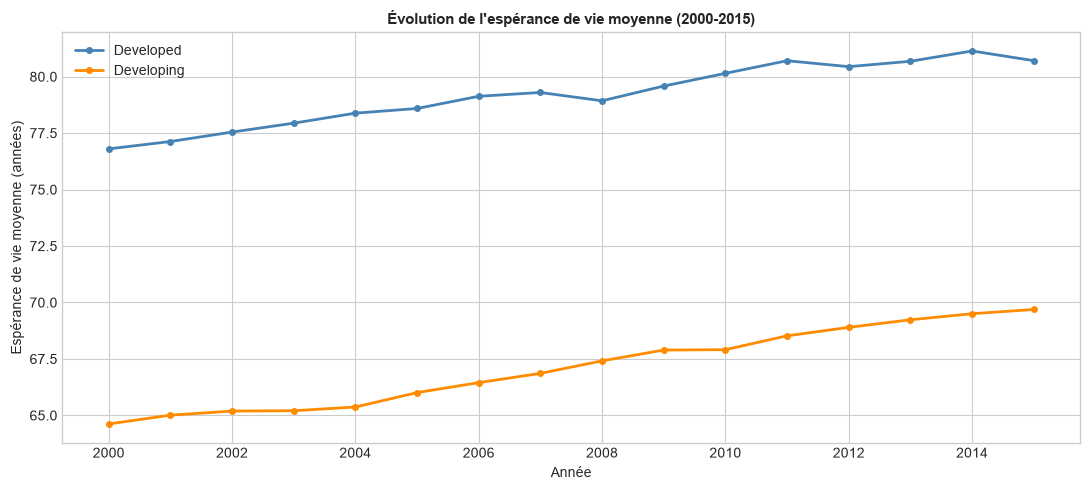

Écart moyen en 2000 : 12.2 ans
Écart moyen en 2015 : 11.0 ans


In [ ]:
evolution = (
    df.groupby(['Year', 'Status'])['Life expectancy']
   .mean()
   .unstack()
)

fig, ax = plt.subplots(figsize=(11, 5))

for status, color in zip(['Developed', 'Developing'], ['steelblue', 'darkorange']):
    if status in evolution.columns:
        evolution[status].plot(
            ax=ax, linewidth=2, marker='o', markersize=4,
            label=status, color=color
        )

ax.set_title("Évolution de l'espérance de vie moyenne (2000-2015)",
             fontweight='bold', fontsize=11)
ax.set_xlabel('Année')
ax.set_ylabel('Espérance de vie moyenne (années)')
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'evolution_temporelle.png', dpi=150, bbox_inches='tight')
plt.show()

ecart_2000 = evolution.loc[2000, 'Developed'] - evolution.loc[2000, 'Developing']
ecart_2015 = evolution.loc[2015, 'Developed'] - evolution.loc[2015, 'Developing']

print(f"Écart moyen en 2000 : {ecart_2000:.1f} ans")
print(f"Écart moyen en 2015 : {ecart_2015:.1f} ans")

## Limites de l'analyse

Cette analyse est exploratoire et plusieurs limites doivent être gardées à l'esprit.

Les corrélations et coefficients observés sont des associations statistiques
dans ce dataset ;ils ne permettent pas de conclure à des relations causales.

Les données sont agrégées au niveau national et annuel. Plusieurs observations
appartiennent au même pays sur plusieurs années, ce que les modèles utilisés
ici ne prennent pas complètement en compte. Des modèles à effets mixtes
seraient plus adaptés pour traiter cette dépendance.

Les résultats décrivent la période 2000 à 2015 et les indicateurs disponibles
dans ce dataset. Ils ne doivent pas être automatiquement généralisés.

Enfin, ce projet n'est pas une construction de table de mortalité.
Il ne modélise pas directement des probabilités de décès par âge,
qui est le vrai objet de la tarification en assurance-vie.

## Ce que j'ai appris

Ce projet m'a appris que la nature longitudinale des données change
la façon dont on doit construire le train et le test. Un découpage aléatoire
n'est pas adapté quand les mêmes entités apparaissent plusieurs fois dans le temps.
Utiliser GroupShuffleSplit pour séparer par pays entiers m'a semblé
beaucoup plus honnête sur le plan méthodologique.

J'ai aussi compris pourquoi il faut standardiser après la séparation
et non avant. Calculer la moyenne et l'écart-type sur tout le dataset
avant de séparer revient à laisser les données de test influencer
l'entraînement ce qu'on appelle une fuite de données.
Le pipeline sklearn règle ce problème proprement.

Sur le fond, ce projet m'a aidée à réfléchir à la différence
entre association et causalité, et à l'intérêt de l'analyse
de la mortalité dans un contexte d'assurance-vie.